# 09 · Gold standard dla etykiet LLM (Ollama) – `hate`, `hate_migrant`, `migrant`

Notebook 08 sprawdzał na gold standardzie **nasze klasyfikatory** (HerBERT, Polbert, RoBERTa-BAN-PL), które dają tylko
etykietę `hate`. Analizy zespołu (`notebooks/hate_analysis/`) opierają się na **etykietach LLM** z
`data/interim/<platforma>/<wydarzenie>/labeled/`. LLM daje trzy etykiety: hejt ogólny, hejt wobec migrantów i
„komentarz o migracji”. Tutaj sprawdzamy, na ile te etykiety zgadzają się z gold standardem
(`data/annotation/gold/gold.csv`: 600 komentarzy, po 200 z platformy, etykiety `hate` i `hate_migrants`).

**Etykiety LLM – dokładnie tak, jak liczą je analizy zespołu** (`notebooks/hate_analysis/cross_platform_hate_analysis.ipynb`
i notebooki per wydarzenie):

| etykieta | Wykop (`labeled/` z kolumnami `llm_is_*`) | YouTube, Bluesky (`labeled/` = tylko komentarze o migracji) |
|---|---|---|
| `migrant` | komentarz z `topic/` **i** `llm_is_about_migration` | komentarz jest w `labeled/` |
| `hate_migrant` | komentarz z `topic/` **i** (`llm_is_hate_migrants` **lub** słownik `hate_migrants_auto`) | w `labeled/` **i** (`llm_is_hate_migrants` / `model_hate_migrants` / `human_hate_migrants`) |
| `hate` | `llm_is_hate_general` **lub** słownik `hate_auto` **lub** `hate_migrant` | w `labeled/` **i** (`llm_is_hate` / `model_hate` / `human_hate`) **lub** `hate_migrant` |

**Uwaga o YouTube i Bluesky.** `scripts/topic_sample.py` zapisuje do `labeled/` tylko komentarze, które regex i LLM uznały
za dotyczące migracji. Codebook każe wtedy wpisać `hate = 0` dla komentarzy spoza migracji. Komentarz z gold, którego nie ma w
`labeled/`, dostaje więc `migrant = hate_migrant = hate = 0` (jak w analizach zespołu). Na tych platformach LLM-owe `hate`
oznacza zatem **hejt w komentarzach o migracji**, a gold `hate` – hejt ogólny. Raportujemy to osobno (sekcja 3).

**Pokrycie.** Etykiety LLM są tylko dla części wydarzeń (Wykop 7, YouTube 7, Bluesky 3), więc z 600 komentarzy gold
ocenić można tylko te z wydarzeń z `labeled/` (sekcja 1). Opcjonalnie (`RUN_OLLAMA_FOR_MISSING = True`, sekcja 6) można
oznaczyć brakujące komentarze gold lokalną Ollamą tym samym promptem co `scripts/topic_sample.py`. Kod zespołu
importujemy, ale go nie zmieniamy.

Wyniki: `reports/gold_llm_eval/` – `gold_llm_labels.csv` (etykiety LLM dla komentarzy gold, bez treści) i `llm_metrics.csv`.
Porównanie LLM z HerBERT / Polbert / RoBERTa dla `hate`: notebook `10_hate_models_vs_llm.ipynb`.

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
GOLD = "data/annotation/gold/gold.csv"
OUT_DIR = "reports/gold_llm_eval"
N_BOOT = 2000
SEED = 2026

# opcjonalnie: brakujące komentarze gold (wydarzenia bez labeled/) oznacz lokalną Ollamą tym samym promptem
RUN_OLLAMA_FOR_MISSING = False
OLLAMA_MODEL = "qwen2.5:7b"          # domyślny w scripts/topic_sample.py – potwierdź z zespołem, jakiego modelu użyto
OLLAMA_HOST = "http://localhost:11434"
OLLAMA_BATCH = 15

In [2]:
import json, re, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.classifier.hate_models import flag_frame, read_csv   # słownik obelg zespołu (scripts/preprocess_slurs.py)

OUT = ROOT / OUT_DIR
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", 220)

gold = read_csv(ROOT / GOLD)
for c in ("hate", "hate_migrants"):
    assert gold[c].isin(["0", "1"]).all(), f"puste etykiety {c} w gold.csv"
gold["gold_hate"] = gold["hate"].astype(int)
gold["gold_hate_migrant"] = gold["hate_migrants"].astype(int)
print(f"gold: {len(gold)} komentarzy | hate=1: {gold['gold_hate'].mean():.1%} | hate_migrants=1: {gold['gold_hate_migrant'].mean():.1%}")
display(gold.groupby("platform")[["gold_hate", "gold_hate_migrant"]].agg(["sum", "mean"]).round(3))


def scores(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    npv = tn / (tn + fn) if tn + fn else 0.0
    f1n = 2 * npv * spec / (npv + spec) if npv + spec else 0.0
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return {"n": len(y), "accuracy": (tp + tn) / len(y) if len(y) else np.nan, "precision": prec, "recall": rec,
            "f1": f1, "specificity": spec, "macro_f1": (f1 + f1n) / 2, "mcc": (tp * tn - fp * fn) / den if den else 0.0,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def boot_ci(y, p, metric="f1", n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y, int), np.asarray(p, int)
    if len(y) < 5:
        return [np.nan, np.nan]
    vals = [scores(y[i], p[i])[metric] for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(vals, [0.025, 0.975]).round(3).tolist()


NUM = ["accuracy", "precision", "recall", "f1", "specificity", "macro_f1", "mcc"]

gold: 600 komentarzy | hate=1: 56.2% | hate_migrants=1: 28.8%


gold_hate        gold_hate_migrant       
               sum   mean               sum   mean
platform                                          
bluesky         69  0.345                16  0.080
wykop          125  0.625                65  0.325
youtube        143  0.715                92  0.460

## 1. Etykiety LLM dla komentarzy z gold standardu

In [3]:
HATE_COLS = ["llm_is_hate", "model_hate", "human_hate"]                              # YouTube, Bluesky
HATE_MIGRANT_COLS = ["llm_is_hate_migrants", "model_hate_migrants", "human_hate_migrants"]


def to_bool(s):
    # NaN -> "nan" -> False (bez fillna, które w nowym pandas ostrzega o rzutowaniu typów)
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def read_labeled(path):
    lab = pd.read_csv(path, encoding="utf-8-sig", dtype={"comment_id": str})
    if not isinstance(lab.index, pd.RangeIndex):
        # jak w cross_platform_hate_analysis: w bluesky:Atak_Kamienna_Gora nagłówek nie ma nazwy "parent_context"
        cols = list(lab.columns)
        i = cols.index("post_context") + 1
        lab = lab.reset_index()
        lab.columns = [*cols[:i], "parent_context", *cols[i:]]
        lab["comment_id"] = lab["comment_id"].astype(str)
    return lab.drop_duplicates("comment_id").set_index("comment_id")


def event_labels(platform, event_folder):
    """Etykiety LLM wydarzenia (indeks = comment_id) + reguła dla komentarzy spoza labeled/."""
    d = ROOT / "data" / "interim" / platform / event_folder
    f = d / "labeled" / "comments_corrected.csv"
    if not f.exists():
        f = d / "labeled" / "comments.csv"
    if not f.exists():
        return None, None
    lab = read_labeled(f)
    out = pd.DataFrame(index=lab.index)
    if platform == "wykop":
        tf = d / "topic" / "comments.csv"
        if tf.exists():
            topic = set(pd.read_csv(tf, encoding="utf-8-sig", usecols=["comment_id"], dtype=str)["comment_id"])
            in_topic = pd.Series(lab.index.isin(topic), index=lab.index)
        else:
            in_topic = pd.Series(True, index=lab.index)
        hm_any = flag(lab, ["llm_is_hate_migrants", "hate_migrants_auto"])
        out["llm_migrant"] = in_topic & flag(lab, ["llm_is_about_migration"])
        out["llm_hate_migrant"] = in_topic & hm_any
        out["llm_hate"] = flag(lab, ["llm_is_hate_general", "hate_auto"]) | hm_any
        err = (lab.get("llm_source", pd.Series("", index=lab.index)).astype(str) == "error") | \
              lab["llm_is_about_migration"].isna()
        out["llm_status"] = np.where(err, "błąd LLM", "etykieta LLM")
        rule_outside = "brak w labeled (Wykop)"          # nie wiemy, co LLM by powiedział -> wyłączamy
    else:
        out["llm_migrant"] = True
        out["llm_hate_migrant"] = flag(lab, HATE_MIGRANT_COLS)
        out["llm_hate"] = flag(lab, HATE_COLS) | out["llm_hate_migrant"]
        out["llm_status"] = "etykieta LLM"
        rule_outside = "poza labeled → 0"                 # regex/LLM: nie o migracji -> 0/0/0 (jak w analizach)
    out["llm_source_file"] = str(f.relative_to(ROOT))
    return out, rule_outside


rows = []
cache = {}
for _, r in gold.iterrows():
    key = (r["platform"], r["event_folder"])
    if key not in cache:
        cache[key] = event_labels(*key)
    lab, rule_outside = cache[key]
    row = {"item_id": r["item_id"]}
    if lab is None:
        row.update(llm_status="brak etykiet LLM dla wydarzenia")
    elif r["comment_id"] in lab.index:
        row.update(lab.loc[r["comment_id"]].to_dict())
    elif rule_outside == "poza labeled → 0":
        row.update(llm_status=rule_outside, llm_migrant=False, llm_hate_migrant=False, llm_hate=False,
                   llm_source_file=str(Path("data/interim") / key[0] / key[1] / "labeled"))
    else:
        row.update(llm_status=rule_outside)
    rows.append(row)
g = gold.merge(pd.DataFrame(rows), on="item_id", how="left")
g["llm_covered"] = g["llm_status"].isin(["etykieta LLM", "poza labeled → 0"])
for c in ("llm_hate", "llm_hate_migrant", "llm_migrant"):
    g[c] = g[c].map({True: 1, False: 0, 1: 1, 0: 0})

cov = (g.groupby(["platform", "llm_status"]).size().unstack(fill_value=0))
cov["razem"] = cov.sum(axis=1)
display(cov)
print(f"Ocena możliwa dla {int(g['llm_covered'].sum())} z {len(g)} komentarzy gold "
      f"({', '.join(f'{p}: {int(s)}' for p, s in g[g['llm_covered']].groupby('platform').size().items())})")
print("\nWydarzenia z etykietami LLM:", sorted({k[0] + '/' + k[1][11:] for k, v in cache.items() if v[0] is not None}))

llm_status,brak etykiet LLM dla wydarzenia,brak w labeled (Wykop),etykieta LLM,poza labeled → 0,razem
platform,,,,,
bluesky,133,0,20,47,200
wykop,90,8,102,0,200
youtube,107,0,49,44,200


Ocena możliwa dla 262 z 600 komentarzy gold (bluesky: 67, wykop: 102, youtube: 93)

Wydarzenia z etykietami LLM: ['bluesky/Atak_Kamienna_Gora', 'bluesky/Ceuta_Masowe_Przekroczenie', 'bluesky/Dezinformacja_Krakow', 'wykop/Atak_Kamienna_Gora', 'wykop/Bojka_Srem', 'wykop/Ceuta_Masowe_Przekroczenie', 'wykop/Dezinformacja_Krakow', 'wykop/Pakt_Azyl_PE', 'wykop/Smierc_Zolnierza', 'wykop/Strategia_Migracyjna', 'youtube/Atak_Kamienna_Gora', 'youtube/Bojka_Srem', 'youtube/Ceuta_Masowe_Przekroczenie', 'youtube/Dezinformacja_Krakow', 'youtube/Pakt_Azyl_PE', 'youtube/Smierc_Zolnierza', 'youtube/Strategia_Migracyjna']


## 2. Metryki: LLM vs gold (`hate`, `hate_migrant`)

Klasa pozytywna = 1. CI 95% dla F1 z bootstrapu. Gold był losowany warstwowo (pule `mig_hostile`, `mig_other`, `ambiguous`
– `scripts/annotation_sample.py`), więc metryki dotyczą tej próby, a nie wszystkich komentarzy; podajemy je też per pula.

In [4]:
TASKS = {"hate": ("gold_hate", "llm_hate"), "hate_migrant": ("gold_hate_migrant", "llm_hate_migrant")}
ev = g[g["llm_covered"]].copy()


def metric_rows(data, label_scope):
    out = []
    for task, (yc, pc) in TASKS.items():
        y, p = data[yc].values, data[pc].astype(int).values
        out.append({"etykieta": task, "zakres": label_scope, **scores(y, p), "f1_ci95": boot_ci(y, p),
                    "gold_pos %": round(100 * y.mean(), 1), "llm_pos %": round(100 * p.mean(), 1)})
    return out


rows = metric_rows(ev, "ogółem")
for plat, d in ev.groupby("platform"):
    rows += metric_rows(d, plat)
for pool, d in ev.groupby("pool"):
    rows += metric_rows(d, f"pula: {pool}")
llm_metrics = pd.DataFrame(rows)
llm_metrics[NUM] = llm_metrics[NUM].astype(float).round(3)
cols = ["zakres", "n", "gold_pos %", "llm_pos %", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc"]
for task in TASKS:
    print(f"\n=== {task} ===")
    display(llm_metrics[llm_metrics["etykieta"] == task][cols].set_index("zakres"))


=== hate ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,262,59.9,34.7,0.618,0.813,0.471,0.597,"[0.524, 0.664]",0.318
bluesky,67,40.3,22.4,0.612,0.533,0.296,0.381,"[0.187, 0.556]",0.143
wykop,102,63.7,43.1,0.716,0.909,0.615,0.734,"[0.626, 0.823]",0.492
youtube,93,69.9,34.4,0.516,0.812,0.400,0.536,"[0.418, 0.647]",0.179
pula: ambiguous,50,80.0,48.0,0.600,0.917,0.550,0.687,"[0.54, 0.8]",0.280
pula: mig_hostile,104,75.0,44.2,0.596,0.891,0.526,0.661,"[0.554, 0.75]",0.291
pula: mig_other,108,36.1,19.4,0.648,0.524,0.282,0.367,"[0.204, 0.524]",0.166



=== hate_migrant ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,262,33.6,30.5,0.702,0.562,0.511,0.536,"[0.446, 0.622]",0.318
bluesky,67,9.0,14.9,0.851,0.300,0.500,0.375,"[0.0, 0.667]",0.309
wykop,102,35.3,41.2,0.686,0.548,0.639,0.590,"[0.447, 0.709]",0.341
youtube,93,49.5,30.1,0.613,0.679,0.413,0.514,"[0.369, 0.641]",0.241
pula: ambiguous,50,34.0,36.0,0.700,0.556,0.588,0.571,"[0.357, 0.75]",0.341
pula: mig_hostile,104,45.2,42.3,0.683,0.659,0.617,0.637,"[0.519, 0.745]",0.356
pula: mig_other,108,22.2,16.7,0.722,0.333,0.250,0.286,"[0.108, 0.468]",0.120


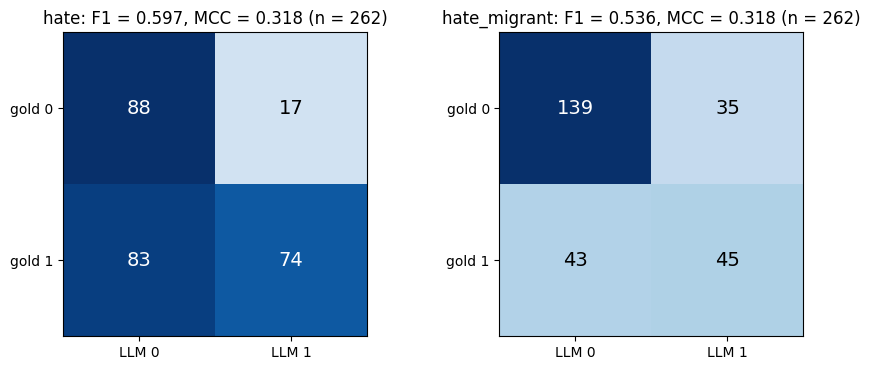

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (task, (yc, pc)) in zip(axes, TASKS.items()):
    s = scores(ev[yc], ev[pc])
    mat = np.array([[s["tn"], s["fp"]], [s["fn"], s["tp"]]])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > mat.max() / 2 else "black")
    ax.set_xticks([0, 1], ["LLM 0", "LLM 1"]); ax.set_yticks([0, 1], ["gold 0", "gold 1"])
    ax.set_title(f"{task}: F1 = {s['f1']:.3f}, MCC = {s['mcc']:.3f} (n = {s['n']})")
plt.tight_layout(); plt.show()

## 3. YouTube i Bluesky: LLM ocenia hejt tylko w komentarzach o migracji

Rozbijamy komentarze gold z tych platform na: (a) obecne w `labeled/` – LLM ocenił hejt, (b) spoza `labeled/` – LLM uznał,
że nie dotyczą migracji, więc `hate = 0`. Duża liczba gold `hate = 1` w (b) to hejt, którego LLM z założenia nie liczy
(np. hejt na polityków). Nie jest to błąd modelu, tylko inna definicja – w porównaniu z HerBERT-em (notebook 10) trzeba to uwzględnić.

In [6]:
yb = ev[ev["platform"].isin(["youtube", "bluesky"])]
if len(yb):
    t = (yb.groupby(["platform", "llm_status"])
           .agg(n=("item_id", "size"), gold_hate=("gold_hate", "sum"), gold_hate_migrant=("gold_hate_migrant", "sum"),
                llm_hate=("llm_hate", "sum"), llm_hate_migrant=("llm_hate_migrant", "sum")))
    display(t)
    inside = yb[yb["llm_status"] == "etykieta LLM"]
    print("Tylko komentarze, które LLM uznał za migracyjne (obecne w labeled/):")
    display(pd.DataFrame(metric_rows(inside, "YouTube+Bluesky, w labeled/"))[cols + ["etykieta"]].set_index("etykieta").round(3))

n  gold_hate  gold_hate_migrant  llm_hate  llm_hate_migrant
platform llm_status                                                                    
bluesky  etykieta LLM      20          8                  3      15.0              10.0
         poza labeled → 0  47         19                  3       0.0               0.0
youtube  etykieta LLM      49         37                 32      32.0              28.0
         poza labeled → 0  44         28                 14       0.0               0.0

Tylko komentarze, które LLM uznał za migracyjne (obecne w labeled/):


,zakres,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
etykieta,,,,,,,,,,
hate,"YouTube+Bluesky, w labeled/",69,65.2,68.1,0.652,0.723,0.756,0.739,"[0.626, 0.835]",0.219
hate_migrant,"YouTube+Bluesky, w labeled/",69,50.7,55.1,0.580,0.579,0.629,0.603,"[0.455, 0.725]",0.159


## 4. Etykieta `migrant` (komentarz o migracji)

Gold nie ma osobnej etykiety „o migracji”, ale komentarz z `hate_migrants = 1` z definicji dotyczy migrantów. Sprawdzamy więc,
jaką część takich komentarzy LLM oznaczył jako `migrant` (czułość tematu) oraz jak często LLM oznacza `migrant` w każdej puli
(pule `mig_*` zawierają słowa o migracji, `ambiguous` – nie).

In [7]:
pos = ev[ev["gold_hate_migrant"] == 1]
print(f"gold hate_migrants = 1: {len(pos)} komentarzy, LLM migrant = 1 w {pos['llm_migrant'].mean():.1%}")
display(ev.groupby(["platform", "pool"])["llm_migrant"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "LLM migrant %"})
        .assign(**{"LLM migrant %": lambda d: (100 * d["LLM migrant %"]).round(1)}))

# hejt trafiony przez LLM: czy dobrze wskazał cel (migranci vs inni)?
both = ev[(ev["gold_hate"] == 1) & (ev["llm_hate"] == 1)]
if len(both):
    s = scores(both["gold_hate_migrant"], both["llm_hate_migrant"])
    print(f"\nKomentarze, które gold i LLM uznały za hejt (n = {len(both)}): zgodność celu (migranci tak/nie) "
          f"accuracy = {s['accuracy']:.3f}, F1(hate_migrant) = {s['f1']:.3f}")

gold hate_migrants = 1: 88 komentarzy, LLM migrant = 1 w 77.3%


n  LLM migrant %
platform pool                          
bluesky  ambiguous    16           37.5
         mig_hostile  27           22.2
         mig_other    24           33.3
wykop    ambiguous    14           71.4
         mig_hostile  44           79.5
         mig_other    44           90.9
youtube  ambiguous    20           70.0
         mig_hostile  33           51.5
         mig_other    40           45.0


Komentarze, które gold i LLM uznały za hejt (n = 74): zgodność celu (migranci tak/nie) accuracy = 0.649, F1(hate_migrant) = 0.776


## 5. Błędy LLM (do przejrzenia)

In [8]:
txt = "text" if "text" in ev.columns else None
for task, (yc, pc) in TASKS.items():
    e = ev[ev[yc] != ev[pc]].assign(błąd=lambda d: np.where(d[pc] == 1, "FP (LLM: tak)", "FN (LLM: nie)"))
    print(f"\n{task}: {len(e)} błędów")
    display(e.groupby(["platform", "błąd"]).size().unstack(fill_value=0))
    if txt:
        display(e.sort_values(["błąd", "platform"])[["item_id", "platform", "llm_status", "błąd", txt]].head(25))


hate: 100 błędów


błąd,FN (LLM: nie),FP (LLM: tak)
platform,,
bluesky,19,7
wykop,25,4
youtube,39,6


,item_id,platform,llm_status,błąd,text
23,P0024,bluesky,poza labeled → 0,FN (LLM: nie),"To zakała ludzkości, nieważne jaki ma odcień czy brunatny czy czarny czy przechodzący w czerwień, nieważne jak lokalnie się nazywa i nieważne jak kogoś innego nazywają bo taki ..."
55,P0056,bluesky,poza labeled → 0,FN (LLM: nie),"jak oni wszyscy. Stąd pogarda dla ""wykształciuchów"" i gloryfikacja głupoty, lenistwa, postaw roszczeniowych. Tym kupili i nadal posiadają ponad 1/3 Polaków"
84,P0085,bluesky,poza labeled → 0,FN (LLM: nie),Sugerował aby państwo pomagało im sprzedawać towary gdyż nie mają możliwości dostać dobrej ceny za to co wyprodukowali. Roszczeniowi jak zwykle.
87,P0088,bluesky,poza labeled → 0,FN (LLM: nie),Używając wobec tych osobników nazw różnych zwierząt co bardzo nas kusi... W sumie jest niesprawiedliwe.\nEwentualnie pozostają niektóre owady a najlepszą nazwą na nich byłyby n...
174,P0175,bluesky,poza labeled → 0,FN (LLM: nie),"Tak, to ciekawe, bo w tak lubiany przez prawaków imperializm też był w sumie niezły. (OK, musiał łyknąć Afganistan, ale wciąż)"
227,P0228,bluesky,poza labeled → 0,FN (LLM: nie),To się dzialo I będzie dziać.\nZawsze można odpowiedzieć jak Erdogan i stracić to paskudztwo.\nOlać protesty i mieć spokój na jakiś czas. Ruscy nie latają już nad Turcja bez po...
262,P0263,bluesky,poza labeled → 0,FN (LLM: nie),"naplet smierdzacy , kawał huja i dziada , brudas smierdzacy."
264,P0265,bluesky,poza labeled → 0,FN (LLM: nie),"To nie są tacy sami faszyści. Jeden robi to z głupoty, drugi z wyrachowania dba o swój osobisty interes. Tyle, że na ulicy efekt jest dokładnie taki sam…"
269,P0270,bluesky,poza labeled → 0,FN (LLM: nie),"Nikt o tych ludziach nie myślał. Słynne polskie ""jakoś to będzie.\nWykorzystał to kler , konus i reszta hołoty i to tego efekty.\nJak często piszę z prowincja trzeba umieć rozm..."
272,P0273,bluesky,poza labeled → 0,FN (LLM: nie),Z nich się już nie należy śmiać - ich trzeba zamknąć. Faszystowskie gnoje.



hate_migrant: 78 błędów


błąd,FN (LLM: nie),FP (LLM: tak)
platform,,
bluesky,3,7
wykop,13,19
youtube,27,9


,item_id,platform,llm_status,błąd,text
332,P0333,bluesky,poza labeled → 0,FN (LLM: nie),"🤣😁🤣\nAle czy my musimy być z tego znani.\nA jeszcze dopowiem jedno, że arabowie murzyni z Centralnej Afryki mają dar do nauki języków, polski łykają w ciągu miesiąca w podstawo..."
365,P0366,bluesky,poza labeled → 0,FN (LLM: nie),Gorzej jak UPA bez P 🙃
389,P0390,bluesky,poza labeled → 0,FN (LLM: nie),W jakich dokładnie krajach napływ islamistów i hamasowców doprowadził do “modelowego wzrostu”?\nJeśli chodzi o Polskę to polecam\nmigracje.gov.pl -> Statystyki na mapie świata\...
113,P0114,wykop,etykieta LLM,FN (LLM: nie),"@[user] kiedyś dostałem bana za zdjęcie czarnego kwadratu na białym tle, obraz jakiegoś malarza , w temacie o murzynach"
139,P0140,wykop,etykieta LLM,FN (LLM: nie),"@[user]: na taką skalę były wcześniej wałki? xDSS\n""chłopski rozum""\nPo co obrażasz? Żydleński to się akurat średnio chyba tymi konsekwencjami przejmuje,skoro są notorycznie ła..."
142,P0143,wykop,etykieta LLM,FN (LLM: nie),"@[user]: każdy wie z filmów że zastrzelenie rakiety to pikuś, jakiś nerd na super komputerku analizuje zagrożenie w 10 sekund a następnie generał za plecami wydaje rozkaz wciśn..."
170,P0171,wykop,etykieta LLM,FN (LLM: nie),@[user]: podziękuj cpunowi z Kijowa. Po ostatnich badaniach opini społecznej. Władek z bohaterami upa. Jednoczy Polaków nawet tych pomagających dziczy ze wschodu ze stolicą w K...
195,P0196,wykop,etykieta LLM,FN (LLM: nie),"Skoro Ukraińcy rozjechali się po całym świecie i nie chcą bronić ojczyzny to kto ma to za nich robić. Przegrana Ukrainy to kwestia czasu, niech zgodzą się na rozmowy pokojowe p..."
205,P0206,wykop,etykieta LLM,FN (LLM: nie),Kurdej szatan już rozkładaj nogi bo inzynierzy wjeżdżają
212,P0213,wykop,etykieta LLM,FN (LLM: nie),@[user]: gaz na strajkujących i armatki wodne zawsze się znajdą ale na inżynierów z Erytrei to już tylko przytulanie


## 6. (Opcjonalnie) Ollama dla komentarzy gold z wydarzeń bez `labeled/`

Gdy `RUN_OLLAMA_FOR_MISSING = True` i Ollama działa lokalnie z modelem `OLLAMA_MODEL`, brakujące komentarze gold są oznaczane
**tą samą procedurą co `scripts/topic_sample.py`** (YouTube/Bluesky):
- komentarze z obelgą 1/1 ze słownika – `hate = hate_migrant = 1` bez LLM,
- regex migracyjny (tekst + wpis + komentarz nadrzędny) – jeśli nie pasuje, komentarz jest nie-migracyjny (0/0/0),
- pozostałe – LLM w paczkach (`classify_batch`, prompt z `SHORT_CODEBOOK`); `is_about_migration = 0` → 0/0/0.

Wynik zapisuje się w `reports/gold_llm_eval/ollama_<model>.csv` (ponowne uruchomienie nie pyta drugi raz o te same komentarze).
Uwaga: na Wykopie zespół użył innego skryptu (kolumny `llm_is_*`), więc te etykiety są tylko przybliżeniem dla Wykopu.

In [9]:
ollama_metrics = None
if RUN_OLLAMA_FOR_MISSING:
    import importlib.util
    spec = importlib.util.spec_from_file_location("topic_sample", ROOT / "scripts" / "topic_sample.py")
    ts = importlib.util.module_from_spec(spec); spec.loader.exec_module(ts)       # kod zespołu – bez zmian

    cache_p = OUT / f"ollama_{re.sub(r'[^A-Za-z0-9_.-]', '_', OLLAMA_MODEL)}.csv"
    done = pd.read_csv(cache_p, dtype=str) if cache_p.exists() else pd.DataFrame(columns=["item_id"])
    todo = g[~g["llm_covered"] & ~g["item_id"].isin(done["item_id"])]
    print(f"do oznaczenia Ollamą: {len(todo)} komentarzy (w cache: {len(done)})")

    # kontekst jak w topic_sample.py: wpis (tytuł/tekst) i komentarz nadrzędny z clean/
    ctx = {}
    for (plat, evf), d in todo.groupby(["platform", "event_folder"]):
        cdir = ROOT / "data" / "interim" / plat / evf / "clean"
        posts = read_csv(cdir / "posts.csv").drop_duplicates("post_id").set_index("post_id") if (cdir / "posts.csv").exists() else None
        com = read_csv(cdir / "comments.csv").drop_duplicates("comment_id").set_index("comment_id")
        for _, r in d.iterrows():
            post_full, parent_full = "", ""
            if posts is not None and r["post_id"] in posts.index:
                p = posts.loc[r["post_id"]]
                post_full = (p.get("title") or p.get("text") or "").strip().replace("\n", " ")
            if r["comment_id"] in com.index:
                rep = com.loc[r["comment_id"]].get("reply_to", "")
                if rep and rep in com.index:
                    parent_full = str(com.loc[rep, "text"]).strip().replace("\n", " ")
            ctx[r["item_id"]] = (post_full, parent_full)

    lex = flag_frame(todo[["comment_id", "text"]], "comment_id")
    pre11 = dict(zip(todo["item_id"], (lex["hate_auto"].astype(bool) & lex["hate_migrants_auto"].astype(bool)).values))
    new_rows, to_llm = [], []
    for _, r in todo.iterrows():
        post_full, parent_full = ctx.get(r["item_id"], ("", ""))
        if pre11[r["item_id"]]:
            new_rows.append({"item_id": r["item_id"], "o_migrant": 1, "o_hate": 1, "o_hate_migrant": 1, "o_source": "słownik 1/1"})
        elif not ts.is_potential_migration(r["text"], post_full, parent_full):
            new_rows.append({"item_id": r["item_id"], "o_migrant": 0, "o_hate": 0, "o_hate_migrant": 0, "o_source": "regex: nie o migracji"})
        else:
            to_llm.append({"item_id": r["item_id"], "post_context": post_full[:300], "parent_context": parent_full[:300],
                           "text": r["text"]})
    t0 = time.time()
    for k in range(0, len(to_llm), OLLAMA_BATCH):
        batch = [dict(b, index=i + 1) for i, b in enumerate(to_llm[k:k + OLLAMA_BATCH])]
        labels = ts.classify_batch(OLLAMA_HOST, OLLAMA_MODEL, batch)
        for b, (mig, hate, hm) in zip(batch, labels):
            if mig == "BLAD":
                continue
            mig, hate, hm = int(mig), int(hate), int(hm)
            if mig == 0:
                hate, hm = 0, 0
            new_rows.append({"item_id": b["item_id"], "o_migrant": mig, "o_hate": max(hate, hm), "o_hate_migrant": hm,
                             "o_source": f"ollama:{OLLAMA_MODEL}"})
        print(f"{min(k + OLLAMA_BATCH, len(to_llm))}/{len(to_llm)} ({time.time() - t0:.0f}s)", flush=True)
    done = pd.concat([done, pd.DataFrame(new_rows)], ignore_index=True).drop_duplicates("item_id", keep="last")
    done.to_csv(cache_p, index=False, encoding="utf-8-sig")

    o = done.set_index("item_id")
    m = ~g["llm_covered"] & g["item_id"].isin(o.index)
    for a, b in [("llm_migrant", "o_migrant"), ("llm_hate", "o_hate"), ("llm_hate_migrant", "o_hate_migrant")]:
        g.loc[m, a] = g.loc[m, "item_id"].map(o[b]).astype(int)
    g.loc[m, "llm_status"] = "Ollama (ten notebook): " + g.loc[m, "item_id"].map(o["o_source"])
    g["llm_covered"] = g["llm_hate"].notna()
    full = g[g["llm_covered"]]
    ollama_metrics = pd.DataFrame(metric_rows(full, "ogółem (labeled/ + Ollama)") +
                                  [r for p, d in full.groupby("platform") for r in metric_rows(d, f"{p} (labeled/ + Ollama)")])
    ollama_metrics[NUM] = ollama_metrics[NUM].astype(float).round(3)
    display(ollama_metrics[["etykieta"] + cols])
else:
    print("RUN_OLLAMA_FOR_MISSING = False – oceniamy tylko komentarze z wydarzeń, które mają labeled/.")

RUN_OLLAMA_FOR_MISSING = False – oceniamy tylko komentarze z wydarzeń, które mają labeled/.


## 7. Zapis

In [10]:
keep = ["item_id", "platform", "event_folder", "comment_id", "pool", "gold_hate", "gold_hate_migrant",
        "llm_hate", "llm_hate_migrant", "llm_migrant", "llm_status", "llm_covered"]
g[keep].to_csv(OUT / "gold_llm_labels.csv", index=False, encoding="utf-8-sig")     # bez treści komentarzy
allm = pd.concat([llm_metrics, ollama_metrics]) if ollama_metrics is not None else llm_metrics
allm.to_csv(OUT / "llm_metrics.csv", index=False, encoding="utf-8-sig")
summary = {t: llm_metrics[(llm_metrics["etykieta"] == t) & (llm_metrics["zakres"] == "ogółem")].iloc[0][["n", "f1", "f1_ci95", "mcc"]].to_dict()
           for t in TASKS}
(OUT / "llm_summary.json").write_text(json.dumps({"covered": int(g["llm_covered"].sum()), "n_gold": len(g),
                                                  "ollama_for_missing": RUN_OLLAMA_FOR_MISSING, **summary},
                                                 ensure_ascii=False, indent=2, default=str), encoding="utf-8")
for t, s in summary.items():
    print(f"LLM {t}: F1 = {s['f1']:.3f} {s['f1_ci95']}, MCC = {s['mcc']:.3f} (n = {s['n']})")
print("zapisano:", ", ".join(p.name for p in sorted(OUT.iterdir())))
print("Dalej: 10_hate_models_vs_llm.ipynb – LLM vs HerBERT / Polbert / RoBERTa dla etykiety hate.")

LLM hate: F1 = 0.597 [0.524, 0.664], MCC = 0.318 (n = 262)
LLM hate_migrant: F1 = 0.536 [0.446, 0.622], MCC = 0.318 (n = 262)
zapisano: gold_llm_labels.csv, hate_llm_vs_models.csv, hate_llm_vs_models.md, hate_llm_vs_models.png, hate_llm_vs_models_tests.csv, llm_metrics.csv, llm_summary.json
Dalej: 10_hate_models_vs_llm.ipynb – LLM vs HerBERT / Polbert / RoBERTa dla etykiety hate.


## 8. Lista komentarzy gold bez etykiety LLM (do oznaczenia Ollamą)

`reports/gold_llm_eval/gold_missing_llm.csv` – komentarze z gold, dla których nie ma etykiety LLM. Plik ma tekst komentarza
i kontekst w tej samej postaci co w `scripts/topic_sample.py`: wpis (tytuł/tekst, 300 znaków) i komentarz nadrzędny
(300 znaków). Ostatnie trzy kolumny (`llm_is_about_migration`, `llm_is_hate`, `llm_is_hate_migrants`) są puste – do uzupełnienia
wartościami 0/1 przez osobę z Ollamą (tym samym modelem i promptem co `labeled/`). Plik z uzupełnionymi kolumnami można
wczytać w sekcji 6 zamiast liczyć Ollamą tutaj.

In [11]:
REASON = {"brak etykiet LLM dla wydarzenia": "wydarzenie bez labeled/",
          "brak w labeled (Wykop)": "komentarz nieobecny w labeled/ (Wykop)",
          "błąd LLM": "błąd LLM w labeled/"}
miss = g[~g["llm_covered"]].copy()
miss["powód"] = miss["llm_status"].map(REASON).fillna(miss["llm_status"])
post_ctx, parent_ctx = [], []
for (plat, evf), d in miss.groupby(["platform", "event_folder"], sort=False):
    cdir = ROOT / "data" / "interim" / plat / evf / "clean"
    posts = (read_csv(cdir / "posts.csv").drop_duplicates("post_id").set_index("post_id")
             if (cdir / "posts.csv").exists() else pd.DataFrame())
    com = (read_csv(cdir / "comments.csv").drop_duplicates("comment_id").set_index("comment_id")
           if (cdir / "comments.csv").exists() else pd.DataFrame())
    for idx, r in d.iterrows():
        pc, par = "", ""
        if r["post_id"] in posts.index:
            p = posts.loc[r["post_id"]]
            pc = (p.get("title") or p.get("text") or "").strip().replace("\n", " ")[:300]
        if r["comment_id"] in com.index:
            rep = com.loc[r["comment_id"]].get("reply_to", "")
            if rep and rep in com.index:
                par = str(com.loc[rep, "text"]).strip().replace("\n", " ")[:300]
        post_ctx.append((idx, pc)); parent_ctx.append((idx, par))
miss["post_context"] = pd.Series(dict(post_ctx))
miss["parent_context"] = pd.Series(dict(parent_ctx))
for c in ("llm_is_about_migration", "llm_is_hate", "llm_is_hate_migrants"):
    miss[c] = ""
cols_out = ["item_id", "platform", "event_folder", "comment_id", "post_id", "powód", "post_context", "parent_context",
            "text", "llm_is_about_migration", "llm_is_hate", "llm_is_hate_migrants"]
miss = miss.sort_values(["platform", "event_folder", "item_id"])[cols_out]
miss.to_csv(OUT / "gold_missing_llm.csv", index=False, encoding="utf-8-sig")
print(f"zapisano {OUT.relative_to(ROOT)}/gold_missing_llm.csv: {len(miss)} komentarzy")
display(miss.groupby(["platform", "powód"]).size().rename("komentarze").to_frame())
display(miss.groupby(["platform", "event_folder"]).size().rename("komentarze").to_frame())

zapisano reports/gold_llm_eval/gold_missing_llm.csv: 338 komentarzy


komentarze
platform powód                                             
bluesky  wydarzenie bez labeled/                        133
wykop    komentarz nieobecny w labeled/ (Wykop)           8
         wydarzenie bez labeled/                         90
youtube  wydarzenie bez labeled/                        107

komentarze
platform event_folder                                          
bluesky  2025-06-06_Naloty_ICE_Los_Angeles                   47
         2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie          71
         2026-09-15_Atak_Jaroslaw                            15
wykop    2024-05-28_Atak_Zolnierz_Granica                    23
         2024-09-08_Bojka_Srem                                2
         2024-10-12_Strategia_Migracyjna                      2
         2025-06-06_Naloty_ICE_Los_Angeles                   29
         2025-10-15_Dezinformacja_Krakow                      3
         2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie          28
         2026-07-30_Ceuta_Masowe_Przekroczenie                1
         2026-09-15_Atak_Jaroslaw                            10
youtube  2022-02-24_Atak_Rosji_Ukraina                       10
         2022-05-08_Zabojstwo_Nowy_Swiat                      2
         2023-09-22_Premiera_Zielona_Granica                 15
         2023-10-15_Referendum_Wybory                        11
         2024-05-28_Atak_Zolnierz_Granica                    10
         2025-06-06_Naloty_ICE_Los_Angeles                    7
         2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie          29
         2026-07-27_Wroclaw_Atak                              2
         2026-09-15_Atak_Jaroslaw                            21